# 12. Prediction model

Goal: put the three models together into one forecast that runs from any start time:
**load (nb 06) + solar (nb 09) + battery (nb 10) → battery voltage over the next N hours.**

The load model needs two inputs the forecast doesn't have in advance: **Starlink on/off** and **speed over ground**. Both now come from **nb 04 (comms: the Starlink schedule) and nb 05 (the mission, reverse-engineered)**: the Starlink schedule, the mode plan, and the mission legs with their speeds.

**Part 1. Inputs:** from nb 04 *(the Starlink schedule section moved there)*

**Part 2. Model**
- Forecast = mission (Starlink schedule + the mode lines of nb 05) → load (nb 07: k·v on the line speed, one k for AUTO, one for mode 17, motor off in MANUAL); solar pseudo-forecast (nb 09); battery model (Model B1, nb 10)

**Part 3. Prediction**, small pieces first
1. 24 h pieces, each starting from the measured voltage
2. The whole mission (17 days) in one free run
3. Isolating the error: the same forecast with perfect (measured) solar, perfect load, or both

battery1 = battery, battery2 ("thruster" in Tether) = total load, battery3 = solar.

**Solar:** the **pseudo-forecast** (nb 09 Part 3b): one smooth curve per day, with the fitted daily peaks taken as a weather forecast that came true.

**Load:** the **mission** (nb 05, one line per mode change) with the **per-mode motor curves** of nb 07.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (14, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # W, total load, both links
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a    # W, Starlink rows only

# Starlink sessions: same rule as nb 06 (Starlink messages < 2 min apart = one session)
direct = df[df.communication_mode == "direct"]
session_id = (direct.t.diff() > pd.Timedelta("2min")).cumsum()
sessions = direct.groupby(session_id).t.agg(start="min", end="max").reset_index(drop=True)
sessions["minutes"] = (sessions.end - sessions.start).dt.total_seconds() / 60

MODE_NAMES = {0: "MANUAL", 10: "AUTO", 16: "INITIALISING", 17: "mode 17"}
LINK_COLORS = {"direct": "#1f77b4", "imt": "#ff7f0e", "globalstar": "#2ca02c"}
STARLINK_W = 22                                                  # nb 06
print(f"{len(sessions)} Starlink sessions, {sessions.start.min():%d %b %H:%M} to {sessions.end.max():%d %b %H:%M}")

159 Starlink sessions, 14 Jul 07:43 to 27 Jul 02:05


# Part 1. Inputs

The Starlink schedule, the mode plan and the mission legs are in **nb 04** (Starlink) and **nb 05** (modes, mission). *(The Starlink schedule plot and table that used to be here moved there.)*

# Part 2. Model

Everything comes from a model, nothing from the telemetry except the **starting voltage**. Model numbers are copied by hand from the other notebooks (latest versions, 19 Nov); if those notebooks are refit, update the cell below.

**Inputs from the mission (nb 04/05, `data/mission_*.csv`)**
- **Starlink on/off:** wakes at hh:47 on the scheduled hours for the phase's on-length (8 min every 2 h, then 16 min every 3 h, off after 27 Jul). The deployment phase had no schedule, so it uses its duty cycle: Starlink power × 0.44.
- **Motor on/off and speed:** from the mission (nb 05, `data/mission_modes.csv`): 95 lines, one per change of mode or arming. In **AUTO and mode 17** the motor runs at the line's speed (its median speed over ground); in **MANUAL** (armed or disarmed) the motor is off.

**Load (nb 07 section 4):** P_load = 10 W hotel + 22 W · Starlink + k_mode · v_line

| mode | k (W per m/s) | motor at 1 m/s | load at 1 m/s (Starlink off / on) |
| --- | --- | --- | --- |
| AUTO | 71.3 | 71 W | 81 / 103 W |
| mode 17 | 54.4 | 54 W | 64 / 86 W |
| MANUAL | 0 | 0 W | 10 / 32 W |

**Solar (nb 09): the pseudo-forecast**, one smooth curve per day: peak_day · cos(π(t − 12.7 h)/24 h)^5.5, with the fitted daily peaks taken as the weather forecast (mean 100 W on days without one).

**Battery (nb 10, Model B1, the best free run there with measured inputs: RMSE 0.40 V):** k = 420 Wh/V, η = 1.14, drain −0.31 W, R = 39.2 mΩ, no charging above 25.0 V. η above 1 isn't physical; it's what the data asks for (a sensor calibration offset or a charge/discharge difference, not yet known), see nb 10.
- P_net = η·P_solar − P_load − P_drain
- OCV moves by P_net · dt / k; terminal V = OCV + R · P_net / V
- Start: OCV = measured voltage (median of readings within ± 30 min) − R · I_batt

In [2]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ---- models, copied by hand from the other notebooks (latest: 19 Nov) ----
HOTEL_W = 10                                                       # nb 06 (STARLINK_W = 22 is set above)

# ---- load from the mission (nb 05 + nb 07 section 4): one line per mode/arming change, motor on in AUTO and mode 17 ----
K_MODE = {"AUTO": 71.3, "mode 17": 54.4}                           # nb 07 section 4: k·v on the mission line speed, W per m/s
MISSION = pd.read_csv("../data/mission_modes.csv", parse_dates=["from", "to"])
MISSION["k"] = MISSION["mode"].map(K_MODE).fillna(0.0)             # MANUAL (armed or disarmed), INITIALISING: motor off
MISSION["v"] = np.where(MISSION.k > 0, MISSION["SOG (m/s)"].fillna(0.0), 0.0)

def mission_motor(grid):
    """Speed (m/s) and motor power (W) at each minute from the mission lines: k_mode · v_line in AUTO / mode 17, else 0."""
    idx = np.searchsorted(MISSION["from"].values, grid.values, side="right") - 1
    ok = (idx >= 0) & (grid.values < MISSION["to"].values[idx.clip(0)])
    v = np.where(ok, MISSION.v.values[idx.clip(0)], 0.0)
    k = np.where(ok, MISSION.k.values[idx.clip(0)], 0.0)
    return v, k * v

# ---- solar: the pseudo-forecast (nb 09, Part 3b): one smooth curve per day, shape shared, peak per day ----
# Positions and dates are shifted, so no real weather forecast fits: we treat the fitted daily peaks as the
# forecast and assume it came true. Days with no daylight data (27-30 Jul) get the mean peak.
with open("../data/solar_daily_peaks.csv") as _f:
    _hdr = dict(kv.split("=") for kv in _f.readline().split(";")[-1].split())
T_NOON, L_DAY, P_SHAPE, PEAK_MEAN = (float(_hdr[k]) for k in ["t_noon", "L", "p", "mean_peak_W"])
PEAKS = pd.read_csv("../data/solar_daily_peaks.csv", comment="#", index_col="day").peak_W
PEAKS.index = pd.to_datetime(PEAKS.index).tz_localize("UTC")

def solar_shape(hour):
    x = np.pi * (np.asarray(hour, dtype=float) - T_NOON) / L_DAY
    return np.where(np.abs(x) < np.pi / 2, np.cos(np.clip(x, -np.pi / 2, np.pi / 2)) ** P_SHAPE, 0.0)

def solar_curve(grid):
    """Solar power (W) at each time in `grid`: the pseudo-forecast (day's peak × shared shape)."""
    h = (grid - grid.floor("D")).total_seconds() / 3600
    pk = PEAKS.reindex(grid.floor("D")).fillna(PEAK_MEAN).values
    return pk * solar_shape(h)

def is_night(grid):
    """Night = the pseudo-forecast shape is below 2 % of its peak (about 20:48 to 04:36 UTC)."""
    return solar_shape((grid - grid.floor("D")).total_seconds() / 3600) < 0.02
BATT = dict(k=420.3, eta=1.138, p_drain=-0.312, R=0.03921, v_max=25.0)  # nb 10, Model B1 (best free run with measured inputs)

sl_plan = pd.read_csv("../data/mission_starlink.csv", parse_dates=["from", "to"], keep_default_na=False).rename(columns={"from": "start"})
def mission_inputs(grid):
    """Per-minute Starlink share (0–1), speed (m/s), load and solar power (W) from the mission alone.
    Motor = k_mode · v_line from the mission lines (AUTO / mode 17), 0 in MANUAL."""
    sl = np.zeros(len(grid))
    for r in sl_plan.itertuples():
        inside = (grid >= r.start) & (grid < r.to)
        if r.duty > 0:
            sl[inside] = r.duty
        elif r.wake_hours:
            hrs = [int(h) for h in r.wake_hours.split()]
            mins_after = (grid - grid.floor("h")).total_seconds() / 60 - 47
            sl[inside & grid.hour.isin(hrs) & (mins_after >= 0) & (mins_after < r.on_min)] = 1
    solar = solar_curve(grid)
    v, p_motor = mission_motor(grid)
    return pd.DataFrame({"starlink": sl, "v": v, "P_motor": p_motor, "P_load": HOTEL_W + STARLINK_W * sl + p_motor,
                         "P_solar": solar}, index=grid)

volts = df.dropna(subset=["voltage_battery1_v"]).set_index("t").voltage_battery1_v

def v_at(t, half="30min"):
    """Measured voltage at time t: median of the readings within ± 30 min (Iridium can be 15 min apart)."""
    return volts[t - pd.Timedelta(half): t + pd.Timedelta(half)].median()

# ---- measured inputs, for the isolation test (section 3) ----
MEAS_GRID = pd.date_range(df.t.min().floor("min"), df.t.max().ceil("min"), freq="1min")
_mins = df.set_index("t")[["P_load", "P_solar"]].resample("1min").mean().reindex(MEAS_GRID)
MEAS = pd.DataFrame(index=MEAS_GRID)
MEAS["P_load"] = _mins.P_load.interpolate(method="time").bfill().ffill()          # both links: good coverage
_night = is_night(MEAS_GRID)
_sol = _mins.P_solar.copy()
_sol[_night & _sol.isna()] = 0.0                                                    # no sun at night
LAST_SOLAR = df.dropna(subset=["P_solar"]).t.max()
MEAS["P_solar"] = _sol.interpolate(method="time", limit_area="inside")
MEAS["solar_src"] = np.where(_mins.P_solar.notna(), "measured", np.where(_night, "night (0)", "interpolated"))
MEAS.loc[MEAS.index > LAST_SOLAR, "P_solar"] = np.nan                              # Starlink gone after 27 Jul
MEAS.loc[MEAS.index > LAST_SOLAR, "solar_src"] = "model (no data)"

def forecast(start, hours, v0=None, solar_src="model", load_src="model"):
    """Battery voltage forecast, minute by minute, from `start` for `hours`.
    v0 = starting voltage (default: measured).
    solar_src / load_src = "model" (default) or "measured" (telemetry, for the isolation test).
    Measured solar falls back to the model where there is none (after Starlink stops on 27 Jul)."""
    start = pd.Timestamp(start)
    grid = pd.date_range(start.floor("min"), start + pd.Timedelta(hours=hours), freq="1min")
    f = mission_inputs(grid)
    if load_src == "measured":
        f["P_load"] = MEAS.P_load.reindex(grid).values
    if solar_src == "measured":
        f["P_solar"] = MEAS.P_solar.reindex(grid).fillna(f.P_solar).values
    if v0 is None:
        v0 = v_at(start)
    k, eta, pd_, R, vmax = BATT["k"], BATT["eta"], BATT["p_drain"], BATT["R"], BATT["v_max"]
    V, ocv = np.empty(len(grid)), None
    for i, (pl, ps) in enumerate(zip(f.P_load.values, f.P_solar.values)):
        p_net = eta * ps - pl - pd_
        if ocv is None:
            ocv = v0 - R * p_net / v0
        v = ocv + R * p_net / max(ocv, 1)
        if p_net > 0 and v > vmax:                       # charge cap: extra solar is lost
            p_net = max((vmax - ocv) / R, 0) * vmax
            v = max(min(v, vmax), ocv)
        V[i] = v
        ocv += p_net / 60 / k
    f["V"] = V
    return f

on_ = MISSION.k > 0
print(f"Mission: {len(MISSION)} lines, motor on in {on_.sum()} ({MISSION.hours[on_].sum():.0f} h, mean speed {np.average(MISSION.v[on_], weights=MISSION.hours[on_]):.2f} m/s); "
      f"k AUTO {K_MODE['AUTO']}, mode 17 {K_MODE['mode 17']} W per m/s; solar: pseudo-forecast")
print(f"pseudo-forecast: t_noon {T_NOON} h, L {L_DAY} h, p {P_SHAPE}, {PEAKS.notna().sum()} days with a fitted peak, mean {PEAK_MEAN:.0f} W for the rest")

Mission: 95 lines, motor on in 45 (195 h, mean speed 0.72 m/s); k AUTO 71.3, mode 17 54.4 W per m/s; solar: pseudo-forecast
pseudo-forecast: t_noon 12.7 h, L 24.0 h, p 5.5, 13 days with a fitted peak, mean 100 W for the rest


# Part 3. Prediction

## 1. 24 h pieces

Start at 00:00 UTC each day (14 Jul: first reading at 00:20), take the measured voltage there, and forecast 24 h with the model alone. Each panel is one day: black dots = measured battery voltage, red = forecast (load from the mission, k per mode). Blue shading = the mission says the motor is on (AUTO or mode 17); yellow ticks along the bottom = Starlink on in the forecast. The table below gives the error at the end of each day (actual − forecast) and the RMSE over the day.

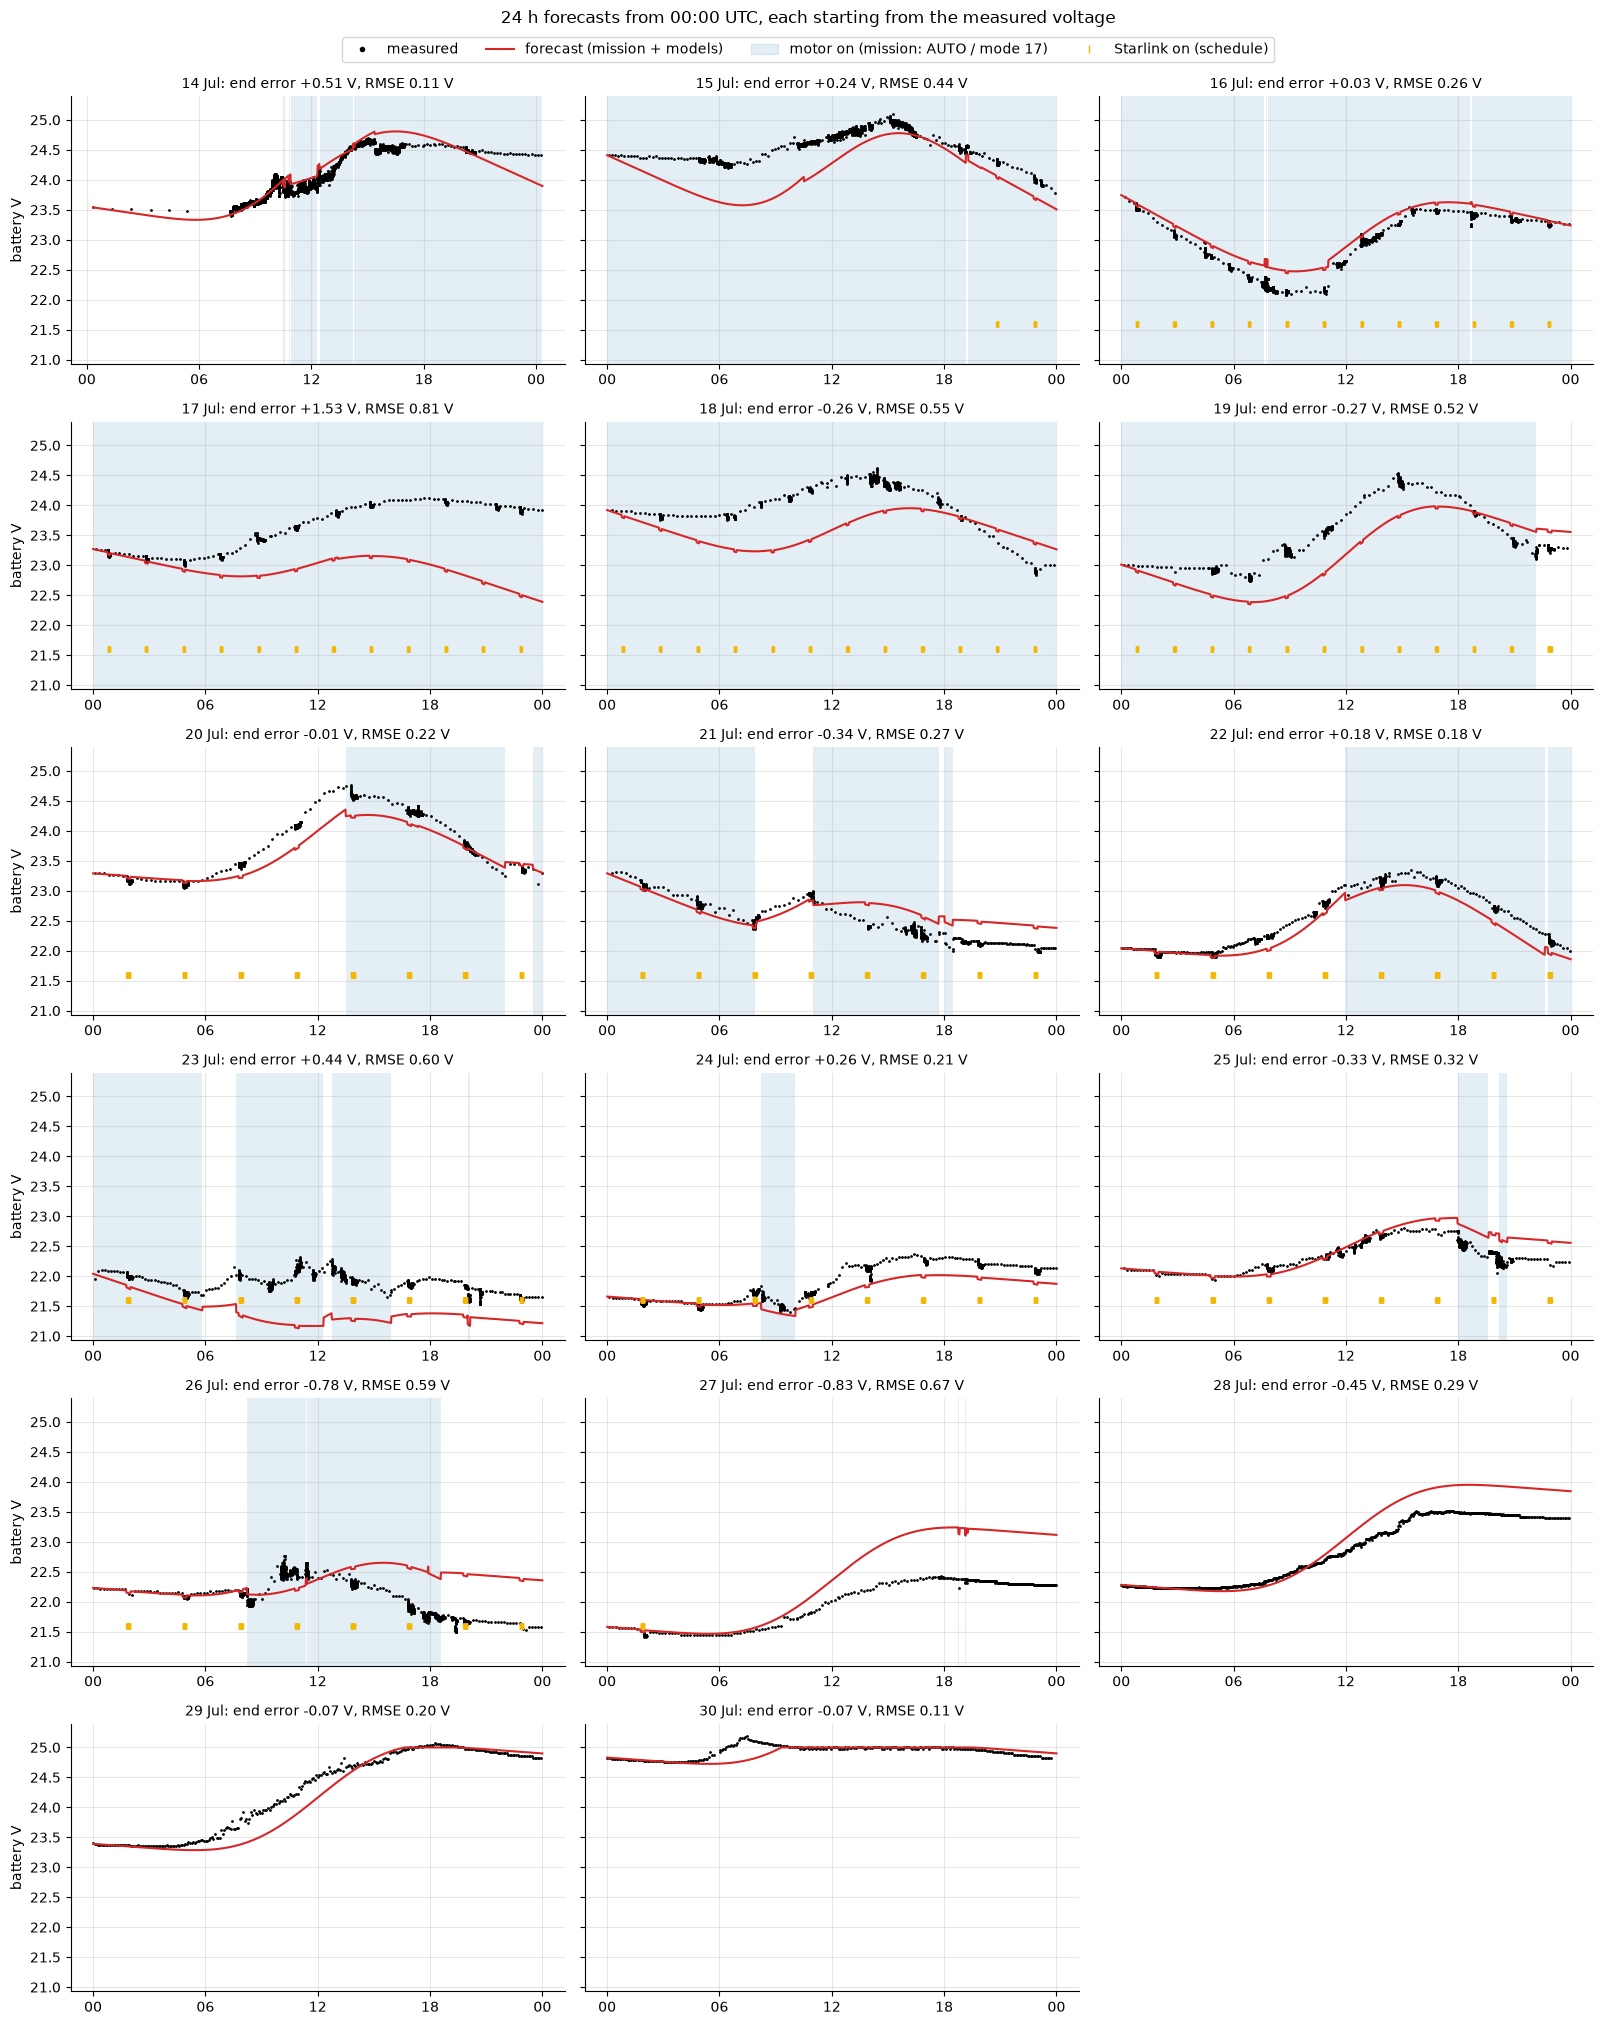

end error over 17 days: mean -0.01 V, mean |error| 0.39 V, RMSE 0.53 V


,V start,V end actual,V end forecast,RMSE (V),motor on (h),end error (V)
day,,,,,,
14 Jul,23.54,24.41,23.90,0.11,13.47,0.51
15 Jul,24.41,23.74,23.51,0.44,23.88,0.24
16 Jul,23.75,23.27,23.24,0.26,23.87,0.03
17 Jul,23.27,23.92,22.39,0.81,24.02,1.53
18 Jul,23.92,23.01,23.27,0.55,24.02,-0.26
19 Jul,23.01,23.29,23.56,0.52,22.18,-0.27
20 Jul,23.29,23.29,23.30,0.22,9.03,-0.01
21 Jul,23.29,22.04,22.38,0.27,15.08,-0.34
22 Jul,22.04,22.04,21.86,0.18,11.88,0.18


In [3]:
days = pd.date_range("2025-07-14", "2025-07-30", tz="UTC")
pieces, rows = {}, []
for d in days:
    start = max(d, volts.index[0])
    f = forecast(start, 24)
    a = volts[start: start + pd.Timedelta("24h")]
    e = a.values - f.V.reindex(a.index.floor("min")).values
    pieces[d] = (f, a)
    rows.append({"day": f"{d:%d %b}", "V start": f.V.iloc[0],
                 "V end actual": v_at(f.index[-1]),
                 "V end forecast": f.V.iloc[-1], "RMSE (V)": np.sqrt(np.nanmean(e ** 2)),
                 "motor on (h)": (f.v > 0).sum() / 60})
res = pd.DataFrame(rows).set_index("day")
res["end error (V)"] = res["V end actual"] - res["V end forecast"]

fig, axes = plt.subplots(6, 3, figsize=(16, 20), sharey=True)
for ax, (d, (f, a)) in zip(axes.flat, pieces.items()):
    on = (f.v > 0).values.astype(int)
    edges = np.flatnonzero(np.diff(np.r_[0, on, 0]))
    for s, e in zip(edges[::2], edges[1::2]):
        ax.axvspan(f.index[s], f.index[e - 1], color="#1f77b4", alpha=0.12, lw=0)
    ax.plot(a.index, a.values, ".", ms=2, color="k")
    ax.plot(f.index, f.V, color="#d62728", lw=1.5)
    sl = f.index[f.starlink >= 1]
    ax.plot(sl, np.full(len(sl), 21.6), "|", ms=5, color="#f2b701")
    r = res.loc[f"{d:%d %b}"]
    ax.set_title(f"{d:%d %b}: end error {r['end error (V)']:+.2f} V, RMSE {r['RMSE (V)']:.2f} V", fontsize=10)
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 6)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H"))
for ax in axes.flat[len(pieces):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("battery V")
fig.legend(handles=[Line2D([], [], marker=".", ls="", color="k", label="measured"),
                    Line2D([], [], color="#d62728", lw=1.5, label=f"forecast (mission + models)"),
                    Patch(color="#1f77b4", alpha=0.12, label="motor on (mission: AUTO / mode 17)"),
                    Line2D([], [], marker="|", ls="", color="#f2b701", label="Starlink on (schedule)")],
           loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"24 h forecasts from 00:00 UTC, each starting from the measured voltage", y=1.01)
plt.tight_layout(); plt.show()

print(f"end error over {len(res)} days: mean {res['end error (V)'].mean():+.2f} V, "
      f"mean |error| {res['end error (V)'].abs().mean():.2f} V, RMSE {np.sqrt((res['end error (V)'] ** 2).mean()):.2f} V")
res.round(2)

**What we see (24 h pieces, load from the mission with k per mode, solar pseudo-forecast, battery B1):**
- **End error: mean −0.01 V, mean |error| 0.39 V, RMSE 0.53 V.** No bias left.
- **Good days** (|end error| ≤ 0.1 V): 16, 20, 29, 30 Jul; most others within ±0.35 V.
- **Worst: 17 Jul, +1.53 V (forecast too low).** Mode-17 lines 37 and 39 (16 Jul 11:00 to 17 Jul 13:00, 26 h) have a median speed of 0.29–0.34 m/s, but the motor drew only 2–5 W: the boat was holding and drifting with the current (~0.2–0.3 m/s, nb 08). k·v through zero gives them 16–18 W, about 300 Wh too much that day.
- **Too high: 26 and 27 Jul (−0.8 V).** 27 Jul has no fitted solar peak (mean used); 26 Jul is a mode-17 day.

**Hypothesis:** below about 0.4 m/s the speed over ground is mostly drift, so the motor should be ~0 there. *Test:* motor = 0 for lines under 0.4 m/s, or k · (v − v_drift) with v_drift ≈ 0.2–0.3 m/s (nb 08); refit k per mode in nb 07 and rerun.


## 2. The whole mission (17 days) in one free run

One forecast from the first voltage reading (14 Jul 00:20) to the end of the data, never corrected along the way. Top: measured voltage (dots) vs forecast (red), with the mission's motor-on time shaded blue. Bottom: error = actual − forecast, one dot per reading.

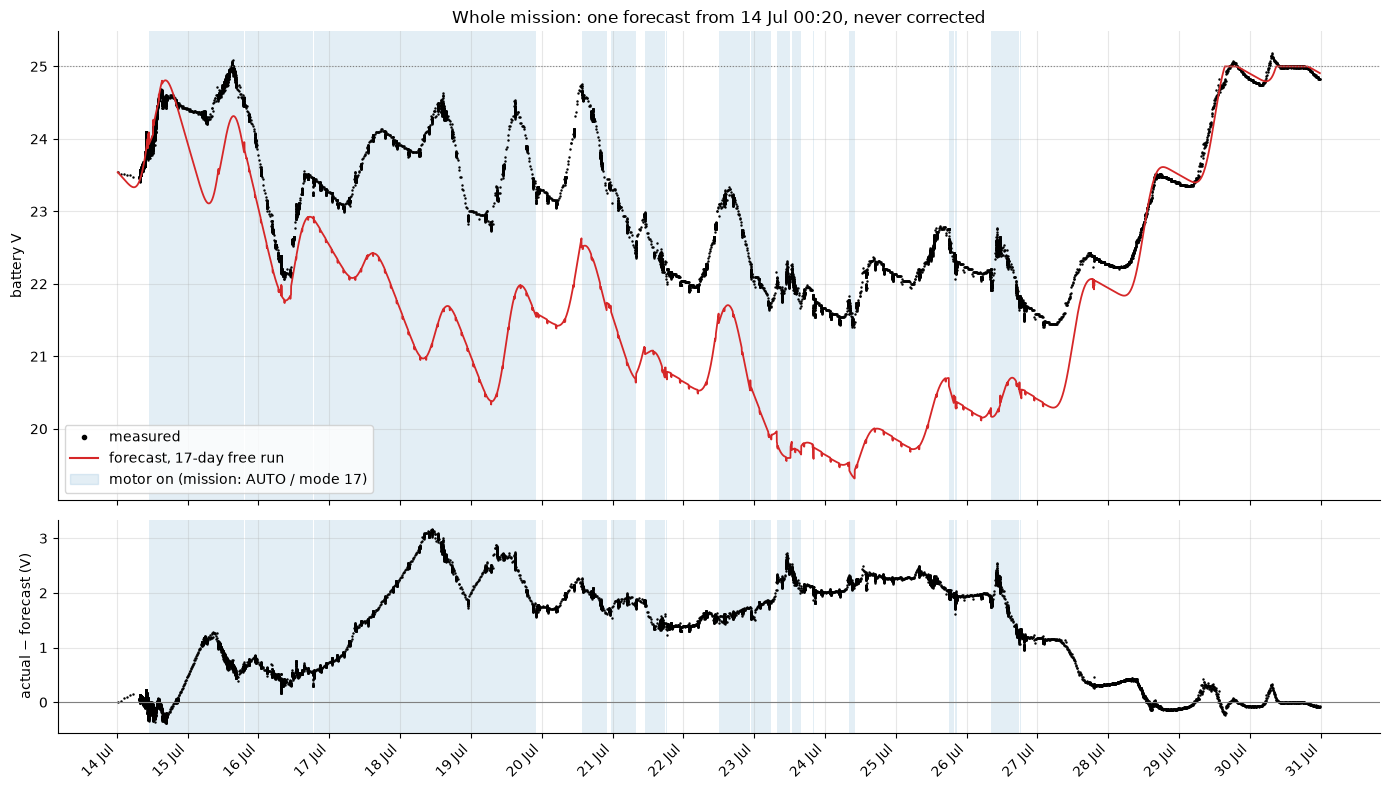

RMSE 1.26 V, mean error +0.85 V, max |error| 3.16 V
forecast energy over 17 days: solar in 15.1 kWh, load out 13.9 kWh (hotel 4.1, Starlink 0.8, propulsion 9.0)
hours at the 25 V cap: forecast 16 h


t,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul,28 Jul,29 Jul,30 Jul
mean error (V),-0.01,0.85,0.47,1.41,2.71,2.31,1.89,1.57,1.54,2.12,2.19,2.03,1.57,0.61,0.15,0.03,-0.0


In [4]:

t0, t1 = volts.index[0], volts.index[-1]
full = forecast(t0, (t1 - t0).total_seconds() / 3600)
err_full = volts.values - full.V.reindex(volts.index.floor("min")).values
err_full = pd.Series(err_full, index=volts.index)

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
on = (full.v > 0).values.astype(int)
edges = np.flatnonzero(np.diff(np.r_[0, on, 0]))
for s, e in zip(edges[::2], edges[1::2]):
    for a in (ax, ax2):
        a.axvspan(full.index[s], full.index[e - 1], color="#1f77b4", alpha=0.12, lw=0)
ax.plot(volts.index, volts.values, ".", ms=1.5, color="k", label="measured")
ax.plot(full.index, full.V, color="#d62728", lw=1.3, label=f"forecast, 17-day free run")
ax.axhline(BATT["v_max"], color="grey", lw=0.8, ls=":")
ax.set_ylabel("battery V")
ax.legend(handles=[Line2D([], [], marker=".", ls="", color="k", label="measured"),
                   Line2D([], [], color="#d62728", lw=1.5, label=f"forecast, 17-day free run"),
                   Patch(color="#1f77b4", alpha=0.12, label="motor on (mission: AUTO / mode 17)")], loc="lower left")
ax.set_title(f"Whole mission: one forecast from 14 Jul 00:20, never corrected")
ax2.plot(err_full.index, err_full.values, ".", ms=1.5, color="k")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_ylabel("actual − forecast (V)")
ax2.xaxis.set_major_locator(mdates.DayLocator()); ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

e_in = full.P_solar.sum() / 60 * BATT["eta"] / 1000
e_out = full.P_load.sum() / 60 / 1000
print(f"RMSE {np.sqrt((err_full ** 2).mean()):.2f} V, mean error {err_full.mean():+.2f} V, max |error| {err_full.abs().max():.2f} V")
print(f"forecast energy over 17 days: solar in {e_in:.1f} kWh, load out {e_out:.1f} kWh "
      f"(hotel {HOTEL_W * len(full) / 60 / 1000:.1f}, Starlink {(STARLINK_W * full.starlink).sum() / 60 / 1000:.1f}, "
      f"propulsion {full.P_motor.sum() / 60 / 1000:.1f})")
print(f"hours at the 25 V cap: forecast {(full.V >= BATT['v_max'] - 0.01).sum() / 60:.0f} h")
daily_err = err_full.groupby(err_full.index.floor("D")).mean()
daily_err.set_axis(daily_err.index.strftime("%d %b")).round(2).to_frame("mean error (V)").T


**What we see (17 days, load from the mission with k per mode, solar pseudo-forecast, battery B1):**
- **RMSE 1.26 V, mean error +0.85 V, max 3.2 V.** The forecast ends up **too low**: it drains faster than the real battery.
- **It drops ~1.4 V too far by 17–18 Jul** (the mode-17 holds of 16–17 Jul counted as motor on, see section 1) and stays about 1.5–2.5 V low until 26 Jul.
- **Energy budget:** 15.1 kWh of solar into the battery vs 13.9 kWh load out (hotel 4.1, motor 9.0, Starlink 0.8). Up to 27 Jul the load is slightly too high (13.0 vs 12.7 kWh measured).
- 16 h at the 25 V cap.


## 3. Isolating the error: perfect solar, perfect load

The 17-day run again, four ways. Battery model and starting voltage are the same in all four; only where solar and load come from changes:

| run | solar | load |
| --- | --- | --- |
| **forecast** (section 2) | pseudo-forecast (nb 09) | model from the mission (nb 07, k per mode) |
| **perfect solar** | measured | model from the mission |
| **perfect load** | model | measured |
| **both measured** | measured | measured |

- **Measured load** = battery1 V × battery2 A, per-minute mean, interpolated between readings. Both links carry it, so it's measured almost everywhere.
- **Measured solar** = battery3 V × A, which only comes over **Starlink**. Between sessions it's interpolated linearly, and set to 0 at night (where the pseudo-forecast is below 2 % of its peak). After Starlink stops for good (27 Jul 02:05) there's no solar data, so all runs use the solar model there (grey band).

If **perfect solar** fixes most of the error, the solar model is the problem; if **perfect load** does, the load model is. **Both measured** shows what's left over for the battery model itself (it's close to the nb 10 free run).

The plot has three panels: voltage, error (actual − forecast, hourly mean), and the **rate of error change** (hour-to-hour change of the hourly error, V per h). A spike in the bottom panel marks an hour where that run goes wrong fastest; positive = the real voltage rose faster (or fell slower) than the run.

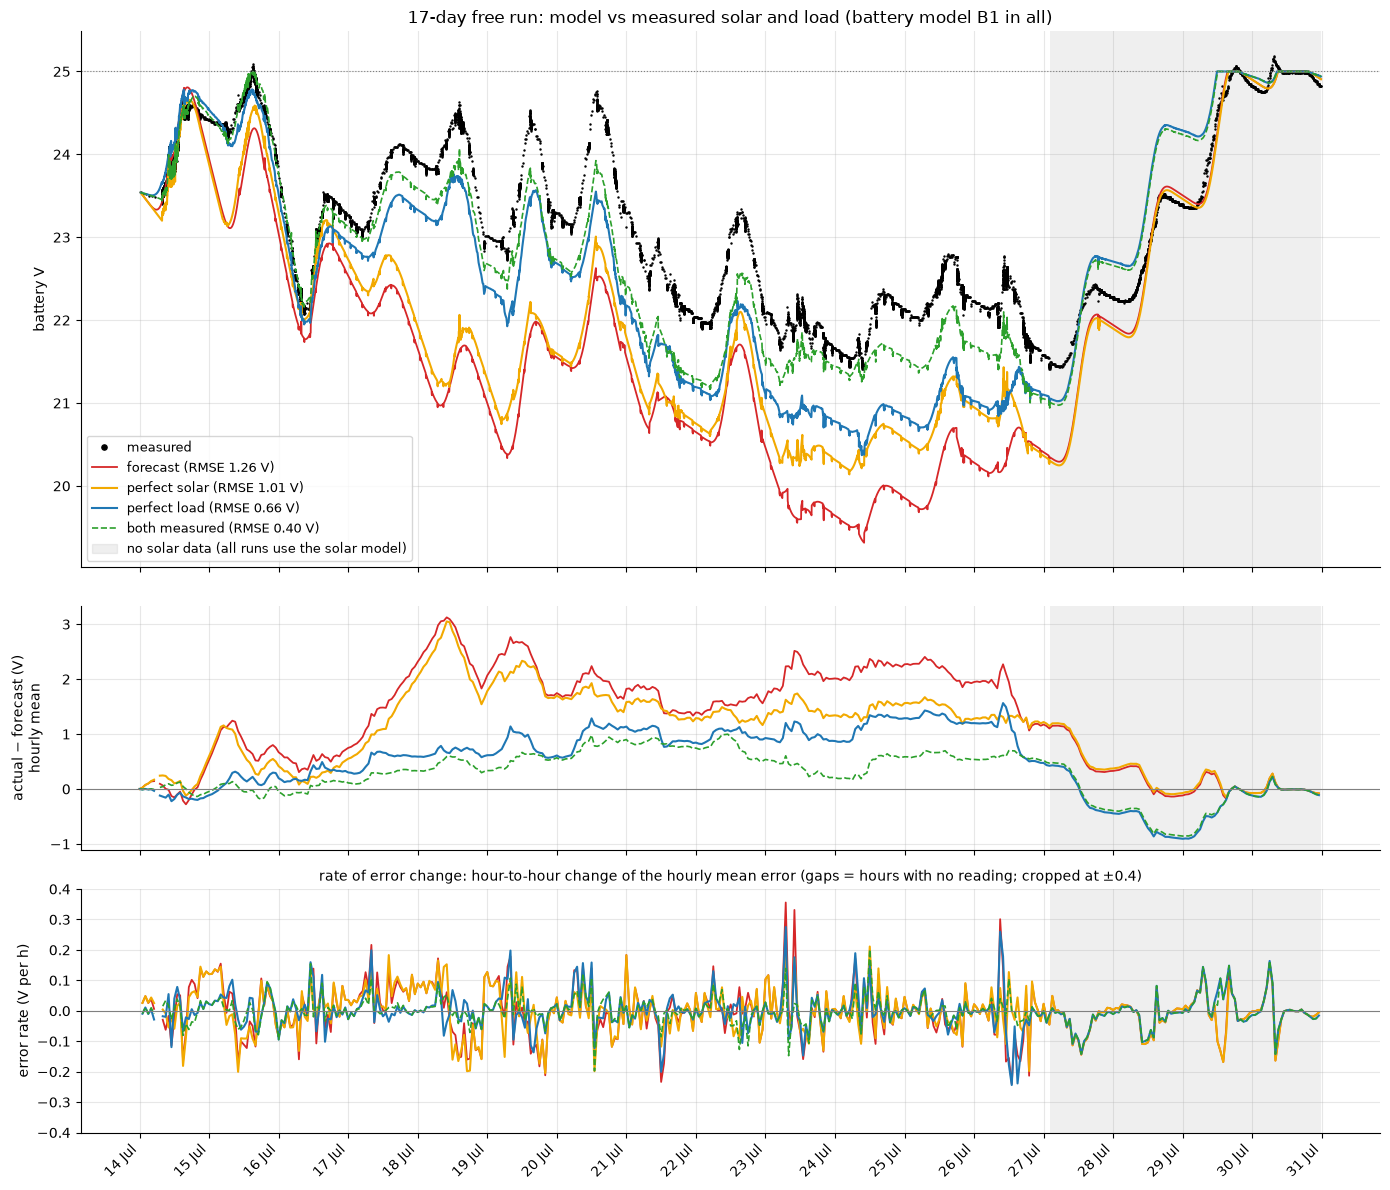

solar minutes to 27 Jul: {'interpolated': 10012, 'night (0)': 5909, 'measured': 2905}


,solar,load,17 days: RMSE (V),to 27 Jul: RMSE (V),to 27 Jul: mean error (V),24 h pieces to 27 Jul: mean |end error| (V),solar in to 27 Jul (kWh),load out to 27 Jul (kWh),hours at 25 V cap
run,,,,,,,,,
forecast,model,model,1.26,1.30,0.89,0.40,11.55,13.00,15.83
perfect solar,measured,model,1.01,1.04,0.78,0.28,11.54,13.00,15.47
perfect load,model,measured,0.66,0.67,0.38,0.23,11.55,12.69,19.87
both measured,measured,measured,0.40,0.40,0.27,0.16,11.54,12.69,20.28


In [5]:
VARIANTS = {"forecast": ("model", "model"), "perfect solar": ("measured", "model"),
            "perfect load": ("model", "measured"), "both measured": ("measured", "measured")}
VAR_STYLE = {"forecast": dict(color="#d62728", lw=1.3), "perfect solar": dict(color="#f2a900", lw=1.5),
             "perfect load": dict(color="#1f77b4", lw=1.5), "both measured": dict(color="#2ca02c", lw=1.2, ls="--")}
hours_all = (t1 - t0).total_seconds() / 3600
runs_v, errs_v = {}, {}
for name, (s_src, l_src) in VARIANTS.items():
    runs_v[name] = forecast(t0, hours_all, solar_src=s_src, load_src=l_src)
    errs_v[name] = pd.Series(volts.values - runs_v[name].V.reindex(volts.index.floor("min")).values, index=volts.index)

fig, (ax, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 12), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1]})
rate_v = {}
for a in (ax, ax2, ax3):
    a.axvspan(LAST_SOLAR, t1, color="grey", alpha=0.12, lw=0)
ax.plot(volts.index, volts.values, ".", ms=1.5, color="k", label="measured")
for name, f in runs_v.items():
    e = errs_v[name]
    ax.plot(f.index, f.V, label=f"{name} (RMSE {np.sqrt((e ** 2).mean()):.2f} V)", **VAR_STYLE[name])
    eh = e.resample("1h").mean()
    ax2.plot(eh.index, eh.values, **VAR_STYLE[name])
    rate_v[name] = eh.diff()                       # V per h; NaN across hours with no reading
    ax3.plot(rate_v[name].index, rate_v[name].values, **VAR_STYLE[name])
ax.axhline(BATT["v_max"], color="grey", lw=0.8, ls=":")
ax.set_ylabel("battery V")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles + [Patch(color="grey", alpha=0.12, label="no solar data (all runs use the solar model)")],
          loc="lower left", fontsize=9, markerscale=5)
ax.set_title("17-day free run: model vs measured solar and load (battery model B1 in all)")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_ylabel("actual − forecast (V)\nhourly mean")
ax3.axhline(0, color="grey", lw=0.8)
ax3.set_ylim(-0.4, 0.4)
ax3.set_ylabel("error rate (V per h)")
ax3.set_title("rate of error change: hour-to-hour change of the hourly mean error (gaps = hours with no reading; cropped at ±0.4)", fontsize=10)
ax3.xaxis.set_major_locator(mdates.DayLocator()); ax3.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.setp(ax3.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

before = volts.index <= LAST_SOLAR
iso = []
for name, f in runs_v.items():
    e = errs_v[name]
    ends = []
    for d in days:
        st = max(d, volts.index[0])
        if st + pd.Timedelta("24h") > LAST_SOLAR:
            continue
        g = forecast(st, 24, solar_src=VARIANTS[name][0], load_src=VARIANTS[name][1])
        ends.append(v_at(g.index[-1]) - g.V.iloc[-1])
    ends = pd.Series(ends).dropna()
    sel = f.index <= LAST_SOLAR
    iso.append({"run": name, "solar": VARIANTS[name][0], "load": VARIANTS[name][1],
                "17 days: RMSE (V)": np.sqrt((e ** 2).mean()),
                "to 27 Jul: RMSE (V)": np.sqrt((e[before] ** 2).mean()), "to 27 Jul: mean error (V)": e[before].mean(),
                "24 h pieces to 27 Jul: mean |end error| (V)": ends.abs().mean(),
                "solar in to 27 Jul (kWh)": (BATT["eta"] * f.P_solar[sel]).sum() / 60 / 1000,
                "load out to 27 Jul (kWh)": f.P_load[sel].sum() / 60 / 1000,
                "hours at 25 V cap": (f.V >= BATT["v_max"] - 0.01).sum() / 60})
print("solar minutes to 27 Jul:", MEAS.loc[MEAS.index <= LAST_SOLAR, "solar_src"].value_counts().to_dict())
pd.DataFrame(iso).set_index("run").round(2)


**What we see (isolation, mission load, solar pseudo-forecast, battery B1):**
- **24 h pieces, mean |end error| to 27 Jul:** forecast 0.40 V, perfect solar 0.28, perfect load 0.23, both measured 0.16. Load and solar now share what's left about equally.
- **Over 17 days, load is still the bigger problem:** perfect load 0.66 V vs perfect solar 1.01 V (forecast 1.26). A small daily load bias builds up.
- **Total energies are now close to the measurements:** solar 11.55 vs 11.54 kWh, load 13.00 vs 12.69 kWh up to 27 Jul. The error left is in *when*, not *how much*.
- **Both measured: RMSE 0.40 V, 0.16 V on 24 h pieces.** The battery model is still fine.


### Which part of the day goes wrong?

The same error rates folded onto one day: for each UTC hour, the mean error rate (V per h) over all days **up to 27 Jul** (after that there's no solar data and every run uses the solar model). Left: mean error rate by hour of day. Right: the same, added up from midnight, i.e. how much error a typical day builds by each hour. The yellow band is when the solar model is above 0 (about 04:30 to 20:30 UTC).

Positive = the real voltage rose faster (or fell slower) than the run; negative = the run rose too fast (too much solar or too little load).

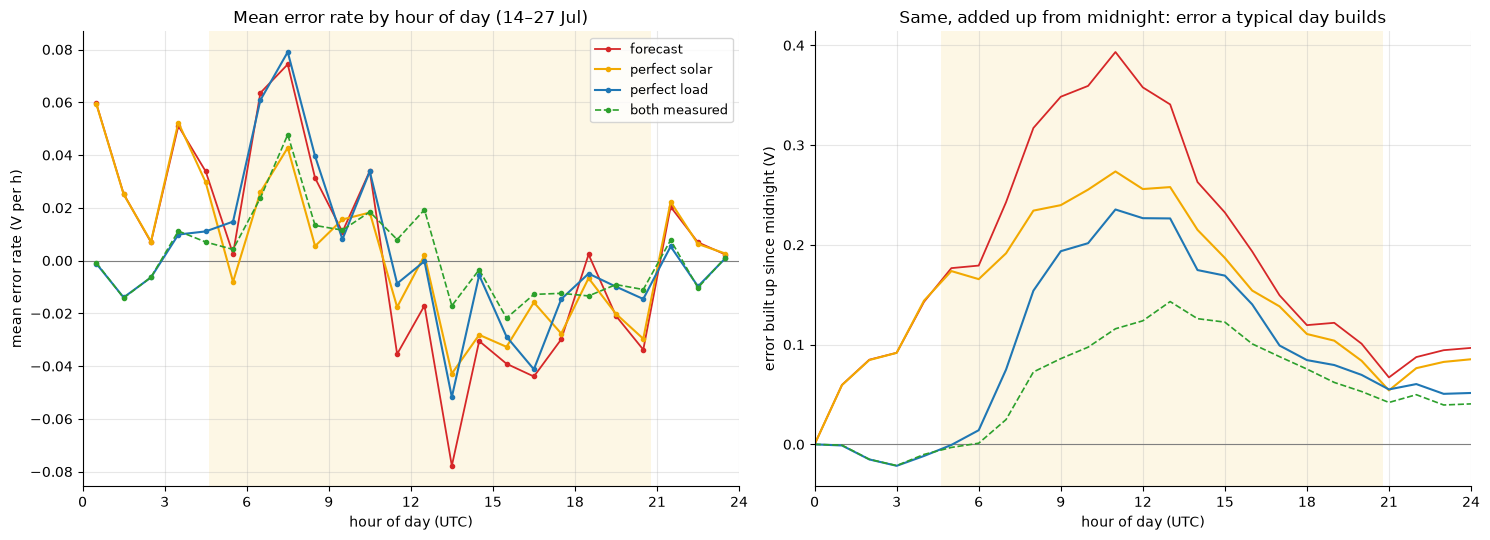

error built per typical day (V), by part of the day (sum of the hourly mean rates):


,night 00–04:30,day 05–20,evening 21–24,whole day
forecast,0.177,-0.110,0.030,0.097
perfect solar,0.174,-0.120,0.031,0.085
perfect load,-0.001,0.056,-0.004,0.051
both measured,-0.003,0.045,-0.001,0.041


In [6]:
hr_rate = {}
for name, r in rate_v.items():
    r = r[r.index <= LAST_SOLAR]
    hr_rate[name] = r.groupby(r.index.hour).agg(["mean", "count"])
hh_ = np.arange(24)
sun = solar_shape(hh_ + 0.5) >= 0.02

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True)
for a in (a1, a2):
    a.axvspan(T_NOON - np.arccos(0.02 ** (1 / P_SHAPE)) * L_DAY / np.pi, T_NOON + np.arccos(0.02 ** (1 / P_SHAPE)) * L_DAY / np.pi, color="#f2b701", alpha=0.10, lw=0)
    a.axhline(0, color="grey", lw=0.8)
for name, t in hr_rate.items():
    a1.plot(t.index + 0.5, t["mean"], marker="o", ms=3, **VAR_STYLE[name], label=name)
    a2.plot(np.r_[0, t.index + 1], np.r_[0, t["mean"].fillna(0).cumsum()], **VAR_STYLE[name], label=name)
a1.set_ylabel("mean error rate (V per h)")
a1.set_title("Mean error rate by hour of day (14–27 Jul)")
a2.set_ylabel("error built up since midnight (V)")
a2.set_title("Same, added up from midnight: error a typical day builds")
for a in (a1, a2):
    a.set_xlim(0, 24); a.set_xticks(range(0, 25, 3)); a.set_xlabel("hour of day (UTC)")
a1.legend(fontsize=9)
plt.tight_layout(); plt.show()

day_tab = pd.DataFrame({name: {"night 00–04:30": t.loc[0:4, "mean"].sum(), "day 05–20": t.loc[5:20, "mean"].sum(),
                               "evening 21–24": t.loc[21:23, "mean"].sum(), "whole day": t["mean"].sum()}
                        for name, t in hr_rate.items()}).T
print("error built per typical day (V), by part of the day (sum of the hourly mean rates):")
day_tab.round(3)

**What we see (time of day, 14–27 Jul, mission load, solar pseudo-forecast, battery B1):**
- **The forecast now goes wrong at night:** +0.18 V per typical night (the real voltage falls slower than the forecast). Perfect solar has the same pattern (+0.17), perfect load none (0.00). So the **night load is too high**: the long mode-17 holds that run through the night (16–17 Jul, and the drifting AUTO/mode-17 lines) are counted as motor on at k·v.
- **During the day it's a bit too high** (−0.11 V per day), and perfect solar is the same (−0.12): daytime load slightly too low.
- They partly cancel: +0.10 V per typical day.
